# Group Project - Time Series Analysis and Forecasting (ASTP) 2026
**MSc in Data Science (ISCTE)**

**Country**: Norway
**Variables Analysed**:
1. **Share Price Index for Norway** (Norwegian stock index - variable of interest)
2. **Brent Crude Oil Price** (Brent oil price - key commodity driver)
3. **USD/NOK Exchange Rate** (USD/NOK exchange rate - monetary variable)

---

## 1. Setup and Data Import
In this section we import the required libraries and load the dataset containing the 3 monthly time series for Norway, obtained directly from the FRED repository.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from statsmodels.tsa.stattools import adfuller, kpss
!pip install arch
!pip install pmdarima
from arch.unitroot import PhillipsPerron
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import coint_johansen
import pmdarima as pm
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Load the merged data from the data/ folder
df = pd.read_csv('data/norway_data.csv', parse_dates=['observation_date'], index_col='observation_date')
print(f"Data loaded successfully! Shape: {df.shape}")
df.head()

  Using cached pmdarima-2.1.1-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (8.5 kB)


  Using cached cython-3.3.0-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (28 kB)


Using cached pmdarima-2.1.1-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (688 kB)
Using cached cython-3.3.0-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (3.4 MB)


Data loaded successfully! Shape: (411, 3)


,Share_Index,USD_NOK,Brent_Oil
observation_date,,,
1992-01-01,9.322927,6.2044,18.156522
1992-02-01,8.923073,6.3472,18.110000
1992-03-01,8.944118,6.5188,17.659091
1992-04-01,8.838893,6.4606,19.015909
1992-05-01,9.554422,6.3311,19.980952


## 2. Descriptive Statistics and Visual Analysis
We split the sample into 90% for training and 10% for testing, and examine the statistical properties of the training set.

Train: 1992-01-01 to 2022-09-01 (369 obs)
Test: 2022-10-01 to 2026-03-01 (42 obs)

Descriptive Statistics (Train):


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Share_Index,369.0,66.798740,52.018538,6.734395,23.283840,60.131310,97.321190,216.426800,0.924498,0.038656
USD_NOK,369.0,7.227708,1.204146,5.054100,6.239700,6.998900,8.270000,10.419900,0.348757,-0.882198
Brent_Oil,369.0,53.006198,32.955381,10.160000,22.178571,48.906364,74.403182,133.585217,0.570522,-0.840191


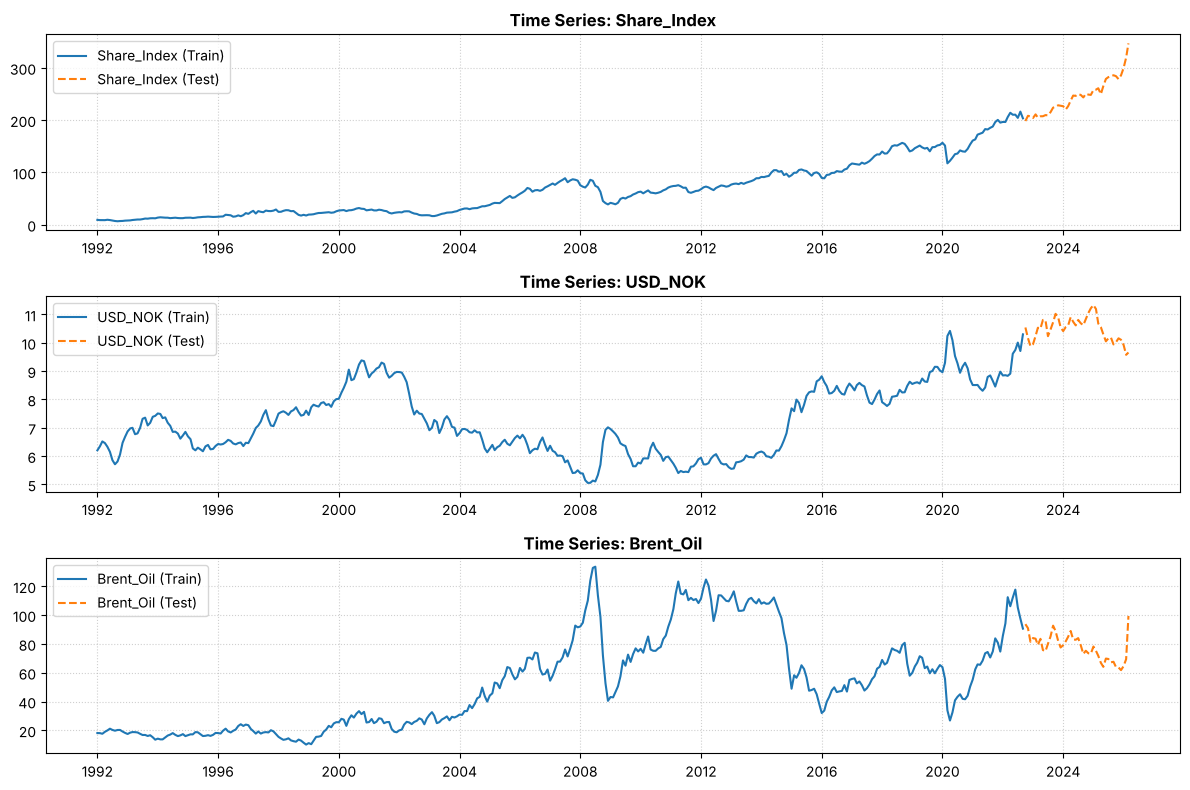

In [2]:
n_obs = len(df)
train_size = int(n_obs * 0.90)
train_df = df.iloc[:train_size]
test_df = df.iloc[train_size:]

print(f"Train: {train_df.index.min().date()} to {train_df.index.max().date()} ({len(train_df)} obs)")
print(f"Test: {test_df.index.min().date()} to {test_df.index.max().date()} ({len(test_df)} obs)")

# Descriptive statistics
desc = train_df.describe().transpose()
desc['skewness'] = train_df.skew()
desc['kurtosis'] = train_df.kurt()
print("\nDescriptive Statistics (Train):")
display(desc)

# Plots
plt.figure(figsize=(12, 8))
for i, col in enumerate(df.columns):
    plt.subplot(3, 1, i+1)
    plt.plot(train_df.index, train_df[col], label=f'{col} (Train)', lw=1.5)
    plt.plot(test_df.index, test_df[col], label=f'{col} (Test)', linestyle='--', lw=1.5)
    plt.title(f'Time Series: {col}', fontweight='bold')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
plt.tight_layout()
plt.show()

## 3. Stationarity Tests (ADF, PP, KPSS)
Stationarity is assessed with 3 different tests:
- **ADF (Augmented Dickey-Fuller)**: H0 = the series has a unit root (non-stationary).
- **PP (Phillips-Perron)**: H0 = the series has a unit root (non-stationary).
- **KPSS**: H0 = the series is stationary (p < 0.05 rejects H0).

If the series are non-stationary in levels, we take the first difference of the natural logarithm.

In [3]:
def check_unit_roots(series):
    adf = adfuller(series.dropna(), autolag='AIC', regression='ct')
    pp = PhillipsPerron(series.dropna(), trend='ct')
    kps = kpss(series.dropna(), regression='ct')
    return {
        'ADF p-val': adf[1],
        'PP p-val': pp.pvalue,
        'KPSS Stat': kps[0], # KPSS p-value is approximate
        'KPSS p-val': kps[1]
    }

print("=== TESTS IN LEVELS ===")
for col in train_df.columns:
    res = check_unit_roots(train_df[col])
    print(f"{col:12} | ADF p={res['ADF p-val']:.4f} | PP p={res['PP p-val']:.4f} | KPSS stat={res['KPSS Stat']:.4f} (p={res['KPSS p-val']:.4f})")

# Take the first difference of the logs
train_diff = np.log(train_df).diff().dropna()
print("\n=== TESTS ON FIRST DIFFERENCE OF LOG ===")
for col in train_diff.columns:
    res = check_unit_roots(train_diff[col])
    print(f"{col:12} (diff) | ADF p={res['ADF p-val']:.4f} | PP p={res['PP p-val']:.4f} | KPSS stat={res['KPSS Stat']:.4f} (p={res['KPSS p-val']:.4f})")

=== TESTS IN LEVELS ===
Share_Index  | ADF p=0.8481 | PP p=0.8815 | KPSS stat=0.4924 (p=0.0100)
USD_NOK      | ADF p=0.9060 | PP p=0.8749 | KPSS stat=0.4298 (p=0.0100)
Brent_Oil    | ADF p=0.1350 | PP p=0.3787 | KPSS stat=0.3471 (p=0.0100)

=== TESTS ON FIRST DIFFERENCE OF LOG ===
Share_Index  (diff) | ADF p=0.0000 | PP p=0.0000 | KPSS stat=0.0291 (p=0.1000)
USD_NOK      (diff) | ADF p=0.0000 | PP p=0.0000 | KPSS stat=0.0855 (p=0.1000)
Brent_Oil    (diff) | ADF p=0.0000 | PP p=0.0000 | KPSS stat=0.0451 (p=0.1000)


/tmp/ipykernel_15735/3320219781.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(series.dropna(), autolag='AIC', regression='ct')
/tmp/ipykernel_15735/3320219781.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kps = kpss(series.dropna(), regression='ct')
/tmp/ipykernel_15735/3320219781.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to a

## 4. Johansen Cointegration Test
Before building a multivariate model, we test for cointegration (a stable long-run relationship in levels) between the series to decide whether to use a **VAR** or a **VECM** model.

In [4]:
train_log = np.log(train_df)
coint_res = coint_johansen(train_log, det_order=0, k_ar_diff=1)
print("Trace Statistics (Johansen):")
for i in range(3):
    print(f"Rank r <= {i}: Trace Stat = {coint_res.lr1[i]:.4f} | 95% Critical Value = {coint_res.cvt[i, 1]:.4f}")
print("\nConclusion: since the statistics are below the critical values, there is no cointegration (r = 0).")
print("We therefore model in first differences using a VAR (Vector Autoregression).")

Trace Statistics (Johansen):
Rank r <= 0: Trace Stat = 15.2973 | 95% Critical Value = 29.7961
Rank r <= 1: Trace Stat = 4.9188 | 95% Critical Value = 15.4943
Rank r <= 2: Trace Stat = 0.6310 | 95% Critical Value = 3.8415

Conclusion: since the statistics are below the critical values, there is no cointegration (r = 0).
We therefore model in first differences using a VAR (Vector Autoregression).


/opt/ds/lib/python3.13/site-packages/statsmodels/tsa/vector_ar/vecm.py:717: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -t * np.sum(tmp, 0)
/opt/ds/lib/python3.13/site-packages/statsmodels/tsa/vector_ar/vecm.py:718: ComplexWarning: Casting complex values to real discards the imaginary part
  lr2[i] = -t * np.log(1 - a[i])


## 5. Model 1: SARIMAX (Univariate with Exogenous Regressor)
We fit a SARIMAX model for the variable of interest `Share_Index`, using `Brent_Oil` (log) as an exogenous variable, with the order selected automatically by the Akaike Information Criterion (AIC).

In [5]:
exog_train = train_log[['Brent_Oil']]
exog_test = np.log(test_df[['Brent_Oil']])

print("Optimising the SARIMAX order with auto_arima...")
sarimax_auto = pm.auto_arima(
    train_log['Share_Index'],
    X=exog_train,
    d=1, seasonal=True, m=12, stepwise=True,
    suppress_warnings=True, error_action="ignore"
)
print(f"Best Model: SARIMAX{sarimax_auto.order}x{sarimax_auto.seasonal_order}")

sarimax_model = SARIMAX(
    train_log['Share_Index'], exog=exog_train,
    order=sarimax_auto.order, seasonal_order=sarimax_auto.seasonal_order,
    enforce_stationarity=False, enforce_invertibility=False
)
sarimax_results = sarimax_model.fit(disp=False)
print(sarimax_results.summary())

# Out-of-sample prediction
sarimax_pred_log = sarimax_results.predict(start=test_df.index[0], end=test_df.index[-1], exog=exog_test)
sarimax_pred = np.exp(sarimax_pred_log)

Optimising the SARIMAX order with auto_arima...


Best Model: SARIMAX(1, 1, 1)x(0, 0, 0, 12)


/opt/ds/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/ds/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:            Share_Index   No. Observations:                  369
Model:               SARIMAX(1, 1, 1)   Log Likelihood                 564.319
Date:                Thu, 29 Oct 2026   AIC                          -1120.637
Time:                        12:30:15   BIC                          -1105.027
Sample:                    01-01-1992   HQIC                         -1114.434
                         - 09-01-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Brent_Oil      0.2898      0.025     11.662      0.000       0.241       0.339
ar.L1         -0.6494      0.072     -9.074      0.000      -0.790      -0.509
ma.L1          0.8120      0.063     12.907      0.0

## 6. Model 2: VAR (Vector Autoregression)
The VAR model captures the multivariate dynamics and two-way feedback between changes in the stock index, Brent oil and the exchange rate.

In [6]:
var_model = VAR(train_diff)
best_lag = var_model.select_order(maxlags=12).aic
print(f"Best lag (AIC): {best_lag}")
var_results = var_model.fit(best_lag if best_lag > 0 else 1)
print(var_results.summary())

# Recursive out-of-sample prediction
var_inputs = train_diff.values[-best_lag:]
var_preds_diff = var_results.forecast(var_inputs, steps=len(test_df))

# Rebuild levels
var_pred = []
last_val_log = train_log['Share_Index'].iloc[-1]
for d_pred in var_preds_diff[:, 0]:
    next_val_log = last_val_log + d_pred
    var_pred.append(np.exp(next_val_log))
    last_val_log = next_val_log
var_pred = pd.Series(var_pred, index=test_df.index)

Best lag (AIC): 2
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 29, Oct, 2026
Time:                     12:30:15
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                   -18.2142
Nobs:                     366.000    HQIC:                  -18.3492
Log likelihood:           1837.19    FPE:                9.82682e-09
AIC:                     -18.4382    Det(Omega_mle):     9.28388e-09
--------------------------------------------------------------------
Results for equation Share_Index
                    coefficient       std. error           t-stat            prob
---------------------------------------------------------------------------------
const                  0.007270         0.003110            2.337           0.019
L1.Share_Index         0.130477         0.058356            2.236           0.025
L1.USD_NOK            -0.036342 

/opt/ds/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


## 7. Model 3: Recurrent Neural Network (LSTM)
We build an LSTM network in PyTorch. The model uses 3 lags of the 3 log-differenced variables to dynamically predict the next log return of the Norwegian stock index.

In [7]:
full_diff = np.log(df).diff().dropna()
train_diff_val = full_diff.iloc[:train_size-1].values
lookback = 3

def create_dataset(data, lookback):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i:i+lookback])
        y.append(data[i+lookback, 0])
    return np.array(X), np.array(y)

X_train, y_train = create_dataset(train_diff_val, lookback)
X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.FloatTensor(y_train).unsqueeze(1)

# LSTM network architecture
class LSTMForecaster(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers=1):
        super(LSTMForecaster, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

model_lstm = LSTMForecaster(input_dim=3, hidden_dim=8)
criterion = nn.MSELoss()
optimizer = optim.Adam(model_lstm.parameters(), lr=0.01)

# Training
model_lstm.train()
for epoch in range(150):
    optimizer.zero_grad()
    out = model_lstm(X_train_t)
    loss = criterion(out, y_train_t)
    loss.backward()
    optimizer.step()
print(f"Training complete! Final loss: {loss.item():.6f}")

# Prediction on the test set
model_lstm.eval()
test_diff_val = full_diff.iloc[train_size-1-lookback:].values
X_test, _ = create_dataset(test_diff_val, lookback)
X_test_t = torch.FloatTensor(X_test)

with torch.no_grad():
    lstm_preds_diff = model_lstm(X_test_t).numpy().flatten()

# Rebuild levels
lstm_pred = []
last_val_log = train_log['Share_Index'].iloc[-1]
for d_pred in lstm_preds_diff[:len(test_df)]:
    next_val_log = last_val_log + d_pred
    lstm_pred.append(np.exp(next_val_log))
    last_val_log = next_val_log
lstm_pred = pd.Series(lstm_pred, index=test_df.index)

Training complete! Final loss: 0.003298


## 8. Out-of-Sample Evaluation and Future Forecast (10 Months)
We compute evaluation metrics (RMSE, MAE, MAPE) for the three models and plot a comparison of the out-of-sample predictions and the future forecasts for 2026.

=== TEST SET PERFORMANCE COMPARISON ===
SARIMAX    | RMSE = 65.5141 | MAE = 53.9044 | MAPE = 20.35%
VAR        | RMSE = 12.9974 | MAE = 7.8856 | MAPE = 2.94%
LSTM       | RMSE = 11.2632 | MAE = 6.8623 | MAPE = 2.61%


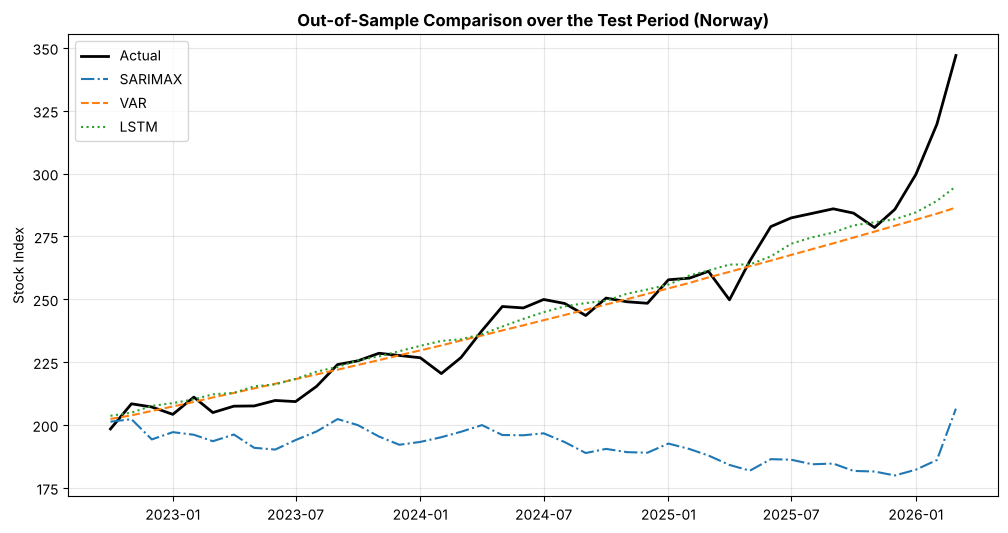

In [8]:
def eval_metrics(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"{name:10} | RMSE = {rmse:.4f} | MAE = {mae:.4f} | MAPE = {mape:.2f}%")
    return {'Model': name, 'RMSE': rmse, 'MAE': mae, 'MAPE': mape}

print("=== TEST SET PERFORMANCE COMPARISON ===")
m1 = eval_metrics(test_df['Share_Index'], sarimax_pred, 'SARIMAX')
m2 = eval_metrics(test_df['Share_Index'], var_pred, 'VAR')
m3 = eval_metrics(test_df['Share_Index'], lstm_pred, 'LSTM')

# Plot the test results
plt.figure(figsize=(12, 6))
plt.plot(test_df.index, test_df['Share_Index'], label='Actual', color='black', lw=2)
plt.plot(test_df.index, sarimax_pred, label='SARIMAX', linestyle='-.')
plt.plot(test_df.index, var_pred, label='VAR', linestyle='--')
plt.plot(test_df.index, lstm_pred, label='LSTM', linestyle=':')
plt.title('Out-of-Sample Comparison over the Test Period (Norway)', fontweight='bold')
plt.ylabel('Stock Index')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()